# Village-wide field boundary delineation

Generates field polygons for **one whole village** using the fine-tuned `ft_best.pt` model (same model, thresholds and post-processing as the standalone inference + split/smooth cells in `ft_inference`).

**Input: a village boundary GeoJSON.** Set `VILLAGE_BOUNDARY_PATH` in the config cell. No coordinates, pins, OpenStreetMap lookups or radius circles are used any more.
- Fields are extracted **only inside the boundary** (fenced during segmentation and clipped to it at the end).
- Imagery is fetched for the boundary's bounding box + a margin (so the model has context at the edges), cached to Drive, and cropped back to the village.
- The file can be GeoJSON (also GPKG / shapefile / KML). If it holds several features, either the union of all of them is used, or `FEATURE_FILTER` picks the village by attribute (e.g. `{'NAME': 'Borgaon Manju'}`).
- If the file has no CRS (plain GeoJSON), it is assumed to be WGS84 (EPSG:4326), as per the GeoJSON spec.

**Run:** Runtime → Change runtime type → **GPU**, then Run all. Check the boundary preview after cell 4 before the long steps run, and re-run from cell 3 if the boundary is wrong.

**Outputs** (in `OUT_DIR` on Drive): `*_fields.gpkg` (UTM 43N), `*_fields.geojson` (WGS84), `*_village_boundary.geojson`, `*_imagery.tif`, `*_preview.png`, `*_run_log.json`.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 1. CONFIG

# INPUT: village boundary GeoJSON (the only thing you must set)
VILLAGE_BOUNDARY_PATH = "/content/drive/MyDrive/CCSB/borgaon_manju.json"
VILLAGE_NAME   = "borgaon_manju"             # None = taken from the file name
SITE_NAME      = "borgaon_manju"             # used in output filenames; None = taken from VILLAGE_NAME
FEATURE_FILTER = None             # None = union of ALL features in the file.
                                  # Or pick one village by attribute, e.g. {'NAME': 'Borgaon Manju'}
                                  # (string match, case-insensitive; several keys must all match)

BOUNDARY_BUFFER_M     = 0.0         # grow (+) / shrink (-) the boundary, in metres
MIN_VILLAGE_HA        = 100

ALLOW_SMALL_BOUNDARY  = False
IMAGERY_MARGIN_M      = 150
CLIP_TO_VILLAGE       = True
MAX_PIXELS            = 400_000_000
BLOCK_PX              = 3072
MARGIN_PX             = 256


# --- derived names (do not edit) -----------------------------------------------
import os, re as _re
if not VILLAGE_BOUNDARY_PATH:
    raise ValueError("Set VILLAGE_BOUNDARY_PATH to your village boundary GeoJSON.")
_stem = os.path.splitext(os.path.basename(VILLAGE_BOUNDARY_PATH))[0]
VILLAGE_NAME = VILLAGE_NAME or _stem
SITE_NAME    = SITE_NAME or _re.sub(r'[^A-Za-z0-9_-]+', '_', VILLAGE_NAME).strip('_').lower()


DRIVE_ROOT = '/content/drive/MyDrive/AI4SF_BD_TF'
CKPT_PATH  = f'{DRIVE_ROOT}/finetune/checkpoints/ft_best.pt'   # fine-tuned model
OUT_DIR    = f'{DRIVE_ROOT}/inference_output/{SITE_NAME}'


UTM_CRS      = 'EPSG:32643'
RES_M        = 1.0
PATCH_PX     = 256
MAX_CHUNK_PX = 1200                 # per-request size for the imagery service


OVERSEG_H        = 0.18
EXTENT_THRESH    = 0.5
MIN_REGION_PX    = 200
DAGGER_WIDTH_M   = 2.0
SIMPLIFY_FIRST_M = 2.0
SMOOTH_METHOD    = 'orthogonal'
ANGLE_TOL_DEG    = 15
SIMPLIFY_AFTER_M = 1.0
SPLIT_OVERSIZED  = True
OVERSIZE_PCTL    = 95
RESCUE_ORPHANS   = True


MIN_FIELD_M2     = 500              # 0.05 ha (~22 x 22 m): below this, edges are pixel noise at 1 m/px
MIN_AREA_FRAC    = 0.10
SMALL_FIELD_HA   = 0.10
MAX_FIELD_HA     = 22.0


# --- v2 extraction: fixes merged fields and boundaries that wander through fields -------------
# SEED_MODE='hminima' + VECTOR_MODE='legacy' reproduces the previous behaviour exactly.
SEED_MODE        = 'cores'     # 'cores': one seed per field CORE (distance head high AND boundary head low)
                               # 'hminima': old -- h-minima of blurred max(boundary, sobel(distance))
SEED_DIST_MIN    = 0.25        # core = normalised distance above this. If narrow strips get merged into
                               #   their neighbours, lower to 0.10-0.15; if fields split, raise to 0.35
SEED_BND_MAX     = 0.30        # ... and boundary prob below this
SEED_MIN_PX      = 30          # ignore seeds smaller than this (px)
EDGE_SIGMA       = 0.7         # blur on the boundary prob (old code: 1.5, which washed out 1-2 m bunds)
DIST_WEIGHT      = 0.3         # where a boundary has a gap, the dividing line follows the distance valley
MERGE_BND_T      = 0.15        # merge touching regions whose shared border has mean boundary prob below
                               #   this -- removes splits with no boundary evidence. 0 = off
LABEL_SMOOTH_R   = 2           # px; removes spikes in raster space while keeping neighbours tiled. 0 = off
VECTOR_MODE      = 'coverage'  # 'coverage': shared edges simplified ONCE for both neighbours (no gaps/
                               #   overlaps, no staircase). Needs geopandas>=1.1 + shapely>=2.1; falls back
                               #   to 'legacy' automatically. 'legacy': old per-polygon simplify/square-up
COVERAGE_TOL_M   = 1.5         # metres; 1.0 = closer to pixels, 2.5 = straighter edges


In [3]:
# 2. SETUP -- install, imports, Drive, model

!pip -q install segmentation-models-pytorch

from google.colab import drive
drive.mount('/content/drive')

import os, io, json, time, gc, hashlib, requests
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

from PIL import Image
from shapely.geometry import shape, Point, Polygon, MultiPolygon
from shapely.ops import unary_union
from shapely.validation import make_valid
from rasterio.features import shapes as rio_shapes, rasterize
from rasterio.transform import from_origin, Affine
from skimage.segmentation import watershed
from skimage.morphology import binary_closing, disk, h_minima
from skimage.filters import sobel
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from tqdm.auto import tqdm

import logging
logging.getLogger('rasterio._env').setLevel(logging.ERROR)

os.makedirs(OUT_DIR, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"device: {device}  |  smp {smp.__version__}  |  torch {torch.__version__}")
if device.type == 'cpu':
    print("WARNING: no GPU -- inference over a whole village will be very slow. "
          "Runtime > Change runtime type > GPU.")


class TripleHeadModel(nn.Module):
    # identical architecture to training. encoder_weights=None: the checkpoint
    # overwrites every weight, so downloading ImageNet weights first is wasted.
    def __init__(self, encoder_name='efficientnet-b4', encoder_weights=None, dropout_p=0.2):
        super().__init__()
        base = smp.Unet(encoder_name=encoder_name, encoder_weights=encoder_weights,
                        in_channels=3, classes=1)
        self.encoder, self.decoder = base.encoder, base.decoder
        dc = base.decoder.blocks[-1].conv2[0].out_channels
        self.extent_dropout = nn.Dropout2d(dropout_p)
        self.boundary_dropout = nn.Dropout2d(dropout_p)
        self.extent_head = nn.Conv2d(dc, 1, 3, padding=1)
        self.boundary_head = nn.Conv2d(dc, 1, 3, padding=1)
        self.distance_head = nn.Conv2d(dc, 1, 3, padding=1)

    def forward(self, x):
        f = self.encoder(x)
        d = self.decoder(f)
        return (self.extent_head(self.extent_dropout(d)),
                self.boundary_head(self.boundary_dropout(d)),
                self.distance_head(d))


assert os.path.exists(CKPT_PATH), f"missing checkpoint: {CKPT_PATH}"
model = TripleHeadModel().to(device)
_ck = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(_ck['model'])
model.eval()
print(f"model loaded (epoch {_ck.get('epoch', '?')})")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 15.8 MB/s eta 0:00:00
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda  |  smp 0.5.0  |  torch 2.11.0+cu130
model loaded (epoch 12)



village         : borgaon_manju
boundary source : file: /content/drive/MyDrive/CCSB/borgaon_manju.json (1 feature)
village area    : 5422 ha (54.22 km2)
imagery grid    : 7330 x 11934 px (87.5 M px) | mosaic in RAM ~0.26 GB | up to 12 blocks of 3072 px (empty ones are skipped)
NOTE: 5422 ha is large for one village -- confirm the boundary file / FEATURE_FILTER selected the right polygon(s).


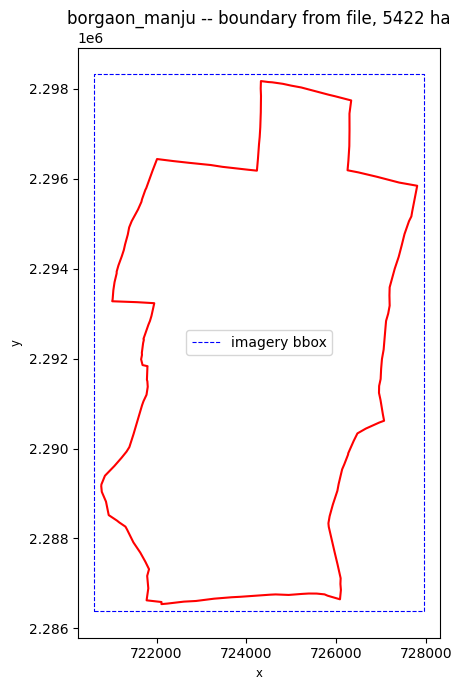

In [4]:
# 3. VILLAGE BOUNDARY -- read from the GeoJSON given in VILLAGE_BOUNDARY_PATH

def _as_polygonal(geom):
    """Valid Polygon/MultiPolygon, or None."""
    if geom is None or geom.is_empty:
        return None
    if not geom.is_valid:
        geom = make_valid(geom)
    if geom.geom_type in ('Polygon', 'MultiPolygon'):
        return geom
    parts = [p for p in (_as_polygonal(g) for g in getattr(geom, 'geoms', [])) if p is not None]
    return unary_union(parts) if parts else None


def load_village_boundary(path, feature_filter=None):
    """Read the boundary file -> (geometry in UTM_CRS, description)."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"VILLAGE_BOUNDARY_PATH not found: {path}")
    gdf = gpd.read_file(path)
    if gdf.crs is None:
        print("  NOTE: file has no CRS -- assuming EPSG:4326 (WGS84 lon/lat), the GeoJSON default.")
        gdf = gdf.set_crs('EPSG:4326')
    n_raw = len(gdf)

    if feature_filter:
        for key, val in feature_filter.items():
            if key not in gdf.columns:
                raise KeyError(f"FEATURE_FILTER key '{key}' not in file attributes: {list(gdf.columns)}")
            gdf = gdf[gdf[key].astype(str).str.strip().str.lower() == str(val).strip().lower()]
        if gdf.empty:
            raise ValueError(f"FEATURE_FILTER {feature_filter} matched none of the {n_raw} features in the file.")
        print(f"  FEATURE_FILTER matched {len(gdf)} of {n_raw} features.")

    gdf = gdf.to_crs(UTM_CRS)
    gdf['geometry'] = gdf.geometry.apply(_as_polygonal)
    gdf = gdf[gdf.geometry.notna()]
    if gdf.empty:
        raise ValueError(f"no polygon features in {path}")

    if len(gdf) > 1:
        print(f"  {len(gdf)} polygon features in the file -> using their UNION as the village. "
              f"If the file holds several villages, set FEATURE_FILTER to select one.")
    geom = _as_polygonal(unary_union(list(gdf.geometry)))
    return geom, f"file: {path} ({len(gdf)} feature{'s' if len(gdf) != 1 else ''})"


village_geom, boundary_desc = load_village_boundary(VILLAGE_BOUNDARY_PATH, FEATURE_FILTER)
boundary_kind = 'file'
village_geom = _as_polygonal(village_geom)
if BOUNDARY_BUFFER_M:
    village_geom = _as_polygonal(village_geom.buffer(BOUNDARY_BUFFER_M))
village_area_ha = village_geom.area / 1e4

# the model was trained in UTM zone 43N; warn if the village is far from it
_c = gpd.GeoSeries([village_geom], crs=UTM_CRS).to_crs('EPSG:4326').iloc[0].centroid
if not (72.0 <= _c.x < 78.0):
    print(f"WARNING: village centroid lon {_c.x:.3f} is outside UTM zone 43 (72E-78E); "
          f"the model was trained in {UTM_CRS}, so results may be distorted.")

print(f"\nvillage         : {VILLAGE_NAME}")
print(f"boundary source : {boundary_desc}")
print(f"village area    : {village_area_ha:.0f} ha ({village_area_ha / 100:.2f} km2)")
if village_area_ha < MIN_VILLAGE_HA and not ALLOW_SMALL_BOUNDARY:
    raise RuntimeError(
        f"Boundary is only {village_area_ha:.1f} ha (< MIN_VILLAGE_HA={MIN_VILLAGE_HA}). That is a fragment, "
        f"not a village -- running on it would give a handful of fields. Fix the boundary file, or set "
        f"ALLOW_SMALL_BOUNDARY=True if it is intentional.")

# --- processing grid: boundary bbox + margin, snapped to whole metres ----------
bminx, bminy, bmaxx, bmaxy = village_geom.bounds
minx = np.floor((bminx - IMAGERY_MARGIN_M) / RES_M) * RES_M
miny = np.floor((bminy - IMAGERY_MARGIN_M) / RES_M) * RES_M
maxx = np.ceil((bmaxx + IMAGERY_MARGIN_M) / RES_M) * RES_M
maxy = np.ceil((bmaxy + IMAGERY_MARGIN_M) / RES_M) * RES_M
w_px, h_px = int(round((maxx - minx) / RES_M)), int(round((maxy - miny) / RES_M))
n_blocks_total = int(np.ceil(w_px / BLOCK_PX) * np.ceil(h_px / BLOCK_PX))
print(f"imagery grid    : {w_px} x {h_px} px ({w_px * h_px / 1e6:.1f} M px) | mosaic in RAM ~{w_px * h_px * 3 / 1e9:.2f} GB "
      f"| up to {n_blocks_total} blocks of {BLOCK_PX} px (empty ones are skipped)")
if w_px * h_px > MAX_PIXELS:
    raise RuntimeError(f"{w_px * h_px:,} px exceeds MAX_PIXELS={MAX_PIXELS:,}. Check the boundary, "
                       f"or raise MAX_PIXELS if you have the RAM.")
if village_area_ha > 3000:
    print(f"NOTE: {village_area_ha:.0f} ha is large for one village -- confirm the boundary file / FEATURE_FILTER "
          f"selected the right polygon(s).")

# --- preview: check this before the long steps ---------------------------------
fig, ax = plt.subplots(figsize=(7, 7))
gpd.GeoSeries([village_geom]).boundary.plot(ax=ax, color='red', linewidth=1.5)
ax.plot([minx, maxx, maxx, minx, minx], [miny, miny, maxy, maxy, miny], 'b--', linewidth=0.8, label='imagery bbox')
ax.set_aspect('equal'); ax.legend(); ax.set_title(f'{VILLAGE_NAME} -- boundary from file, {village_area_ha:.0f} ha')
plt.tight_layout(); plt.show()


In [5]:
# 4. IMAGERY -- Esri World Imagery, native UTM 1 m/px, parallel fetch + Drive cache

from concurrent.futures import ThreadPoolExecutor

ESRI_URL = 'https://services.arcgisonline.com/arcgis/rest/services/World_Imagery/MapServer/export'
FETCH_WORKERS = 4


def fetch_chunk(x0, y0, x1, y1, w, h, retries=4):
    params = {'bbox': f'{x0},{y0},{x1},{y1}', 'bboxSR': 32643, 'imageSR': 32643,
              'size': f'{w},{h}', 'format': 'png32', 'f': 'image'}
    for a in range(retries):
        try:
            r = requests.get(ESRI_URL, params=params, timeout=60)
            r.raise_for_status()
            if 'image' not in r.headers.get('Content-Type', ''):
                raise ValueError(f"non-image response: {r.text[:150]}")
            arr = np.array(Image.open(io.BytesIO(r.content)).convert('RGB')).transpose(2, 0, 1)
            if arr.shape != (3, h, w):
                raise ValueError(f"unexpected tile shape {arr.shape}, wanted {(3, h, w)}")
            return arr
        except Exception as e:
            print(f"    retry {a + 1}/{retries}: {e}")
            time.sleep(2 ** a)
    raise RuntimeError("fetch failed")


def fetch_mosaic(minx, maxy, w_px, h_px, res=RES_M, chunk=MAX_CHUNK_PX, workers=FETCH_WORKERS):
    """Pixel-aligned mosaic; (col, row) offsets are from the top-left corner."""
    mosaic = np.zeros((3, h_px, w_px), dtype=np.uint8)
    cols = list(range(0, w_px, chunk)) + [w_px]
    rows = list(range(0, h_px, chunk)) + [h_px]
    jobs = [(c0, c1, r0, r1) for c0, c1 in zip(cols[:-1], cols[1:]) for r0, r1 in zip(rows[:-1], rows[1:])]

    def work(job):
        c0, c1, r0, r1 = job
        arr = fetch_chunk(minx + c0 * res, maxy - r1 * res, minx + c1 * res, maxy - r0 * res,
                          c1 - c0, r1 - r0)
        return job, arr

    with ThreadPoolExecutor(workers) as ex:
        for (c0, c1, r0, r1), arr in tqdm(ex.map(work, jobs), total=len(jobs), desc='fetching'):
            mosaic[:, r0:r1, c0:c1] = arr
            if arr.std() < 1.0:
                print(f"  WARNING: chunk cols {c0}-{c1}, rows {r0}-{r1} is uniform "
                      f"(likely 'no imagery' placeholder)")
    return mosaic


transform = from_origin(minx, maxy, RES_M, RES_M)
raster_path = f'{OUT_DIR}/{SITE_NAME}_imagery.tif'

mosaic = None
if os.path.exists(raster_path):
    with rasterio.open(raster_path) as src:
        if ((src.width, src.height) == (w_px, h_px) and src.crs is not None
                and src.crs.to_epsg() == 32643
                and abs(src.bounds.left - minx) < 1e-3 and abs(src.bounds.top - maxy) < 1e-3):
            mosaic = src.read()
            print(f"reusing cached imagery: {raster_path}")

if mosaic is None:
    mosaic = fetch_mosaic(minx, maxy, w_px, h_px)
    with rasterio.open(raster_path, 'w', driver='GTiff', dtype='uint8', count=3,
                       height=h_px, width=w_px, crs=UTM_CRS, transform=transform,
                       compress='deflate', tiled=True) as dst:
        dst.write(mosaic)
    print(f"imagery saved: {raster_path}")
print(f"mosaic: {mosaic.shape}")

reusing cached imagery: /content/drive/MyDrive/AI4SF_BD_TF/inference_output/borgaon_manju/borgaon_manju_imagery.tif
mosaic: (3, 11934, 7330)


In [6]:
# 5. INFERENCE FUNCTION -- fast: fp16 autocast, channels_last, large batches (runs per block in cell 8)

USE_FP16   = True      # ~2-3x faster on T4/L4/A100; set False to match fp32 results exactly
BATCH_SIZE = 32        # lower to 16 if you hit CUDA out-of-memory
OVERLAP    = 64        # px; 32 is ~1.4x faster with slightly more seam risk


def predict(model, img_uint8, overlap=OVERLAP, batch_size=BATCH_SIZE, fp16=USE_FP16, progress=True):
    img = img_uint8.astype('float32') / 255.0
    H, W = img.shape[1], img.shape[2]
    stride = PATCH_PX - overlap
    ph = (stride - (H - PATCH_PX) % stride) % stride if H > PATCH_PX else PATCH_PX - H
    pw = (stride - (W - PATCH_PX) % stride) % stride if W > PATCH_PX else PATCH_PX - W
    ip = np.pad(img, ((0, 0), (0, ph + PATCH_PX), (0, pw + PATCH_PX)), mode='reflect')
    del img
    Hp, Wp = ip.shape[1], ip.shape[2]
    acc, wsum = np.zeros((3, Hp, Wp), 'float32'), np.zeros((Hp, Wp), 'float32')
    ramp = np.hanning(PATCH_PX)
    win = np.outer(ramp, ramp).astype('float32') + 1e-6
    coords = [(y, x) for y in range(0, Hp - PATCH_PX + 1, stride)
                     for x in range(0, Wp - PATCH_PX + 1, stride)]
    use_amp = fp16 and device.type == 'cuda'
    with torch.inference_mode():
        for i in tqdm(range(0, len(coords), batch_size), desc='inference', disable=not progress, leave=False):
            bc = coords[i:i + batch_size]
            bi = torch.from_numpy(np.stack([ip[:, y:y + PATCH_PX, x:x + PATCH_PX] for y, x in bc]))
            bi = bi.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                e, b, d = model(bi)
            e = torch.sigmoid(e.float()).cpu().numpy()[:, 0]
            b = torch.sigmoid(b.float()).cpu().numpy()[:, 0]
            d = d.float().cpu().numpy()[:, 0]
            for (y, x), ee, bb, dd in zip(bc, e, b, d):
                acc[0, y:y + PATCH_PX, x:x + PATCH_PX] += ee * win
                acc[1, y:y + PATCH_PX, x:x + PATCH_PX] += bb * win
                acc[2, y:y + PATCH_PX, x:x + PATCH_PX] += dd * win
                wsum[y:y + PATCH_PX, x:x + PATCH_PX] += win
    acc /= np.maximum(wsum, 1e-6)
    return acc[0, :H, :W], acc[1, :H, :W], acc[2, :H, :W]


model = model.to(memory_format=torch.channels_last)
torch.backends.cudnn.benchmark = True

# --- fp16 safety check: compare against fp32 on a crop; fall back to fp32 if they disagree ---
if USE_FP16 and device.type == 'cuda':
    n = 768
    y0, x0 = max(0, (mosaic.shape[1] - n) // 2), max(0, (mosaic.shape[2] - n) // 2)
    crop = mosaic[:, y0:y0 + n, x0:x0 + n]
    e32, b32, d32 = predict(model, crop, fp16=False, progress=False)
    e16, b16, d16 = predict(model, crop, fp16=True, progress=False)
    has_nan = any(np.isnan(a).any() for a in (e16, b16, d16))
    de, db = float(np.abs(e16 - e32).mean()), float(np.abs(b16 - b32).mean())
    ok = (not has_nan) and de < 0.01 and db < 0.01
    print(f"fp16 vs fp32 on crop: mean|diff| extent {de:.4f}, boundary {db:.4f}, NaN={has_nan} -> "
          f"{'fp16 OK' if ok else 'MISMATCH, using fp32'}")
    if not ok:
        USE_FP16 = False

torch.cuda.empty_cache() if device.type == 'cuda' else None

fp16 vs fp32 on crop: mean|diff| extent 0.0003, boundary 0.0001, NaN=False -> fp16 OK


In [7]:
# 6. EXTRACTION FUNCTIONS + village mask + block plan

# Two fixes vs the first version (which returned a single polygon):
#  (a) FENCE: edge strength outside the village is set to its maximum before seeding.
#      Before, a basin whose deepest point lay just OUTSIDE the village produced a seed that
#      was then thrown away, leaving every field in that basin unlabelled.
#  (b) ORPHAN RESCUE: any field-extent area that still got no seed becomes its own region
#      (split_oversized in the next step then tries to break it up).
def drop_small_regions(labels, min_px):
    counts = np.bincount(labels.ravel())
    small = counts < min_px
    small[0] = False
    labels[small[labels]] = 0
    return labels


def extract_instances(extent_prob, boundary_prob, distance_pred, village_mask,
                      extent_thresh=EXTENT_THRESH, overseg_h=OVERSEG_H,
                      min_px=MIN_REGION_PX, rescue_orphans=RESCUE_ORPHANS):
    dist_norm = (distance_pred - distance_pred.min()) / (np.ptp(distance_pred) + 1e-9)
    dist_edges = sobel(gaussian_filter(dist_norm, sigma=1.0))
    dist_edges /= (dist_edges.max() + 1e-9)
    edge_strength = np.maximum(boundary_prob / (boundary_prob.max() + 1e-9), dist_edges)
    edge_smooth = gaussian_filter(edge_strength, sigma=1.5)

    extent_mask = ndi.binary_fill_holes(binary_closing(extent_prob > extent_thresh, disk(2)))
    extent_mask &= village_mask

    fenced = np.where(village_mask, edge_smooth, edge_smooth.max())          # (a)
    markers, _ = ndi.label(h_minima(fenced, overseg_h) & extent_mask)
    labels = watershed(edge_smooth, markers, mask=extent_mask)
    n_seeded = len(np.unique(labels)) - (1 if (labels == 0).any() else 0)

    n_rescued = 0
    if rescue_orphans:                                                        # (b)
        ol, _ = ndi.label(extent_mask & (labels == 0))
        cnt = np.bincount(ol.ravel()); cnt[0] = 0
        keep = cnt >= min_px
        n_rescued = int(keep.sum())
        if n_rescued:
            ol[~keep[ol]] = 0
            labels = np.where(ol > 0, ol + labels.max(), labels).astype(labels.dtype)

    labels = drop_small_regions(labels, min_px)
    info = {'extent_pct_of_village': 100 * extent_mask.sum() / max(village_mask.sum(), 1),
            'labelled_pct_of_extent': 100 * (labels > 0).sum() / max(extent_mask.sum(), 1),
            'seeded_regions': n_seeded, 'rescued_regions': n_rescued,
            'final_regions': len(np.unique(labels)) - (1 if (labels == 0).any() else 0)}
    return labels, edge_smooth, info


# ---------------------------------------------------------------------------------------------
# v2 extraction (SEED_MODE='cores').
# Why the old seeding fails: h-minima on the blurred boundary map only separates two fields if
# the ridge between them is >= OVERSEG_H high ALL the way round. One gap in a bund and the two
# basins become one -> merged fields. sobel(distance) was added to the edge map to compensate,
# but the gradient of a distance map is high on the SLOPES inside every field (and ~0 at the
# real boundary), so it plants false ridges inside fields -> wandering lines and random splits.
# v2 uses the distance head for what it is good at -- finding field cores -- and the boundary
# head only as the flooding surface.
from skimage.segmentation import expand_labels


def _robust_norm(a, mask=None, lo=2, hi=98):
    v = a[mask] if mask is not None and mask.any() else a
    p_lo, p_hi = np.percentile(v, [lo, hi])
    return np.clip((a - p_lo) / (p_hi - p_lo + 1e-9), 0, 1)


def extract_instances_v2(extent_prob, boundary_prob, distance_pred, village_mask,
                         extent_thresh=EXTENT_THRESH, seed_bnd_max=SEED_BND_MAX,
                         seed_dist_min=SEED_DIST_MIN, seed_min_px=SEED_MIN_PX,
                         edge_sigma=EDGE_SIGMA, dist_weight=DIST_WEIGHT,
                         min_px=MIN_REGION_PX, rescue_orphans=RESCUE_ORPHANS):
    """Returns (labels, flooding surface, smoothed boundary prob, info)."""
    # closing with disk(1), not disk(2): a 2-px closing bridges the 1-3 m bunds between fields
    extent_mask = ndi.binary_fill_holes(ndi.binary_closing(extent_prob > extent_thresh, structure=disk(1)))
    extent_mask &= village_mask

    bp = gaussian_filter(boundary_prob.astype('float32'), sigma=edge_sigma) if edge_sigma else boundary_prob
    dist = _robust_norm(gaussian_filter(distance_pred.astype('float32'), 1.0), extent_mask)

    seed_mask = extent_mask & (bp < seed_bnd_max) & (dist > seed_dist_min)
    seed_mask = ndi.binary_opening(seed_mask, structure=disk(1))     # break 1-px bridges between cores
    markers, _ = ndi.label(seed_mask)
    markers = drop_small_regions(markers, seed_min_px)
    n_seeded = len(np.unique(markers)) - 1

    elev = bp + dist_weight * (1.0 - dist)
    labels = watershed(elev, markers, mask=extent_mask)

    n_rescued = 0
    if rescue_orphans:
        ol, _ = ndi.label(extent_mask & (labels == 0))
        cnt = np.bincount(ol.ravel()); cnt[0] = 0
        keep = cnt >= min_px
        n_rescued = int(keep.sum())
        if n_rescued:
            ol[~keep[ol]] = 0
            labels = np.where(ol > 0, ol + labels.max(), labels).astype(labels.dtype)

    labels = drop_small_regions(labels, min_px)
    info = {'extent_pct_of_village': 100 * extent_mask.sum() / max(village_mask.sum(), 1),
            'labelled_pct_of_extent': 100 * (labels > 0).sum() / max(extent_mask.sum(), 1),
            'seeded_regions': n_seeded, 'rescued_regions': n_rescued,
            'final_regions': len(np.unique(labels)) - (1 if (labels == 0).any() else 0)}
    return labels, elev, bp, info


def merge_weak_boundaries(labels, boundary_prob, thresh=MERGE_BND_T, min_contact_px=10, max_area_px=None):
    """Region-adjacency merge: two touching regions are merged when the boundary prob along their
    shared border is weak (mean < thresh). Weakest borders first; never grows a region past max_area_px."""
    if thresh <= 0 or labels.max() == 0:
        return labels, 0
    L, B = labels, boundary_prob
    los, his, vals = [], [], []
    for a, b, va, vb in ((L[:, :-1], L[:, 1:], B[:, :-1], B[:, 1:]),
                         (L[:-1, :], L[1:, :], B[:-1, :], B[1:, :])):
        m = (a != b) & (a > 0) & (b > 0)
        los.append(np.minimum(a[m], b[m])); his.append(np.maximum(a[m], b[m]))
        vals.append(np.maximum(va[m], vb[m]))
    lo, hi, v = (np.concatenate(x) for x in (los, his, vals))
    if lo.size == 0:
        return labels, 0
    n = int(L.max()) + 1
    key = lo.astype(np.int64) * n + hi
    uniq, inv = np.unique(key, return_inverse=True)
    cnt = np.bincount(inv)
    mean = np.bincount(inv, weights=v) / cnt
    cand = np.where((cnt >= min_contact_px) & (mean < thresh))[0]
    cand = cand[np.argsort(mean[cand])]

    parent = np.arange(n)
    area = np.bincount(L.ravel(), minlength=n).astype(np.int64)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    merged = 0
    for c in cand:
        ra, rb = find(int(uniq[c] // n)), find(int(uniq[c] % n))
        if ra == rb or (max_area_px is not None and area[ra] + area[rb] > max_area_px):
            continue
        parent[rb] = ra
        area[ra] += area[rb]
        merged += 1
    root = np.array([find(i) for i in range(n)])
    root[0] = 0
    return root[L].astype(L.dtype), merged


def smooth_labels(labels, radius=LABEL_SMOOTH_R):
    """Raster spike ('dagger') removal that keeps the tiling: open each region with a disk, then
    hand the removed pixels to the nearest surviving neighbour."""
    if radius <= 0 or labels.max() == 0:
        return labels
    fp = disk(radius)
    out = np.zeros_like(labels)
    for i, sl in enumerate(ndi.find_objects(labels), start=1):
        if sl is None:
            continue
        sl = tuple(slice(max(s.start - radius, 0), s.stop + radius) for s in sl)
        m = labels[sl] == i
        o = ndi.binary_opening(m, structure=fp)
        if not o.any():                     # thinner than the disk everywhere: keep as is
            o = m
        out[sl][o] = i
    fg = labels > 0
    filled = expand_labels(out, distance=radius + 1)
    out = np.where(fg & (out == 0), filled, out)
    out[~fg] = 0
    return out


def polygonize_labels(labels, transform, crs):
    out = [(shape(g), int(v)) for g, v in
           rio_shapes(labels.astype('int32'), mask=labels > 0, transform=transform) if v > 0]
    return gpd.GeoDataFrame({'label': [v for _, v in out]}, geometry=[g for g, _ in out], crs=crs)


def make_blocks(village_mask, block=BLOCK_PX):
    """Core tiles (r0, r1, c0, c1) that contain at least one village pixel."""
    H, W = village_mask.shape
    out = []
    for r0 in range(0, H, block):
        for c0 in range(0, W, block):
            r1, c1 = min(r0 + block, H), min(c0 + block, W)
            n = int(village_mask[r0:r1, c0:c1].sum())
            if n:
                out.append((r0, r1, c0, c1, n))
    return out


village_mask = rasterize([(village_geom, 1)], out_shape=mosaic.shape[1:], transform=transform,
                         fill=0, dtype='uint8').astype(bool)
blocks = make_blocks(village_mask)
print(f"village covers {village_mask.mean() * 100:.0f}% of the processed grid "
      f"({village_mask.sum() * RES_M ** 2 / 1e4:.0f} ha) -> {len(blocks)} blocks to process "
      f"(of {int(np.ceil(mosaic.shape[1] / BLOCK_PX) * np.ceil(mosaic.shape[2] / BLOCK_PX))})")

village covers 62% of the processed grid (5422 ha) -> 11 blocks to process (of 12)


In [8]:
# 7. POST-PROCESS FUNCTIONS -- split merged fields, spike removal, simplify, square-up

def split_oversized(labels, edge_img, thresh_m2, px_area,
                    h_ladder=(0.12, 0.08, 0.05, 0.03, 0.02), min_piece_px=200, verbose=True):
    """Retry h-minima seeding inside each oversized region (on its bounding-box crop only),
    stepping h down until it splits into 2+ pieces. Regions that never split stay intact."""
    out = labels.copy()
    next_id = int(labels.max()) + 1
    counts = np.bincount(labels.ravel())
    slices = ndi.find_objects(labels)                       # slices[i] belongs to label i+1
    high = edge_img.max()
    targets = [l for l in range(1, len(counts)) if counts[l] * px_area > thresh_m2]
    n_split = 0
    for lid in tqdm(targets, desc='re-splitting', leave=False, disable=not verbose):
        sl = slices[lid - 1]
        if sl is None:
            continue
        m = labels[sl] == lid
        sub_edge = np.where(m, edge_img[sl], high)          # fence the region off
        for h in h_ladder:
            mk, n = ndi.label(h_minima(sub_edge, h) & m)
            if n < 2:
                continue
            sub = watershed(sub_edge, mk, mask=m)
            pieces = [s for s in np.unique(sub) if s != 0 and (sub == s).sum() >= min_piece_px]
            if len(pieces) < 2:
                continue
            view = out[sl]
            for s in pieces:
                view[(sub == s) & m] = next_id
                next_id += 1
            n_split += 1
            break
    if verbose:
        print(f"split {n_split} of {len(targets)} oversized regions")
    return out


def remove_daggers(poly, max_w=2.0, min_area=20.0):
    """Google ALU 'dagger removal' -- thin inward spikes = narrow notches vs the convex hull."""
    if poly.is_empty or not poly.is_valid:
        return poly
    notches = poly.convex_hull.difference(poly)
    if notches.is_empty:
        return poly
    parts = list(notches.geoms) if hasattr(notches, 'geoms') else [notches]
    fill = [n for n in parts if n.area >= min_area and n.buffer(-max_w / 2).is_empty]
    if not fill:
        return poly
    out = unary_union([poly] + fill)
    return max(out.geoms, key=lambda g: g.area) if isinstance(out, MultiPolygon) else out


def orthogonal_regularize(poly, angle_tol_deg=15):
    """Snap near-axis edges to exactly axis-aligned relative to the polygon's dominant orientation."""
    if poly.is_empty or poly.geom_type != 'Polygon':
        return poly
    mrr = list(poly.minimum_rotated_rectangle.exterior.coords)
    e = np.array(mrr[1]) - np.array(mrr[0])
    base_angle = np.arctan2(e[1], e[0])
    coords = list(poly.exterior.coords)[:-1]
    new_coords = [np.array(coords[0], dtype=float)]
    for i in range(1, len(coords)):
        p0 = new_coords[-1]
        p1 = np.array(coords[i], dtype=float)
        v = p1 - p0
        if np.linalg.norm(v) < 1e-6:
            continue
        ang_deg = np.degrees(np.arctan2(v[1], v[0]) - base_angle) % 180
        nearest_axis = round(ang_deg / 90) * 90
        if abs(ang_deg - nearest_axis) <= angle_tol_deg:
            snapped = base_angle + np.radians(nearest_axis)
            nd = np.array([np.cos(snapped), np.sin(snapped)])
            p1 = p0 + nd * np.dot(v, nd)
        new_coords.append(p1)
    if len(new_coords) < 3:
        return poly
    out = Polygon([tuple(c) for c in new_coords])
    if not out.is_valid:
        out = out.buffer(0)
    if out.geom_type == 'MultiPolygon':
        out = max(out.geoms, key=lambda g: g.area)
    return out if (out.is_valid and not out.is_empty and out.area > poly.area * 0.3) else poly


def n_vertices(gdf):
    return sum(len(g.exterior.coords) for g in gdf.geometry if g.geom_type == 'Polygon')


HAS_COVERAGE = hasattr(gpd.GeoSeries, 'simplify_coverage')     # geopandas>=1.1 with shapely>=2.1
if VECTOR_MODE == 'coverage' and not HAS_COVERAGE:
    print("NOTE: geopandas.GeoSeries.simplify_coverage not available -> VECTOR_MODE falls back to 'legacy'. "
          "`pip install -U 'geopandas>=1.1' 'shapely>=2.1'` and restart to enable it.")


def postprocess_polygons(gdf):
    """'coverage': simplify the block's polygons as ONE tiling, so a shared edge is simplified once
    for both neighbours -> no slivers/overlaps, and the 1-px staircase becomes a straight line.
    (Spikes were already removed in raster space by smooth_labels.)
    'legacy': dagger removal -> simplify -> square-up -> simplify, per polygon."""
    if VECTOR_MODE == 'coverage' and HAS_COVERAGE and len(gdf):
        gdf = gdf.copy()
        try:
            gdf['geometry'] = gdf.geometry.simplify_coverage(COVERAGE_TOL_M, simplify_boundary=True)
            gdf['geometry'] = gdf.geometry.make_valid()
            gdf = gdf.explode(index_parts=False)
            gdf = gdf[gdf.geom_type == 'Polygon']
            return gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty & gdf.geometry.is_valid]
        except Exception as e:                                   # never lose a block over this
            print(f"  coverage simplify failed ({e}); using legacy post-processing for this block")
    gdf = gdf.copy()
    gdf['geometry'] = [remove_daggers(g, DAGGER_WIDTH_M) for g in gdf.geometry]
    gdf['geometry'] = [g.simplify(SIMPLIFY_FIRST_M, preserve_topology=True) for g in gdf.geometry]
    if SMOOTH_METHOD == 'orthogonal':
        gdf['geometry'] = [orthogonal_regularize(g, ANGLE_TOL_DEG) for g in gdf.geometry]
    if SIMPLIFY_AFTER_M > 0:
        gdf['geometry'] = [g.simplify(SIMPLIFY_AFTER_M, preserve_topology=True) for g in gdf.geometry]
    return gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty & gdf.geometry.is_valid]

[1/11] rows 0-3072 cols 0-3072 | village  22% of block | extent 99% -> labelled 100% | regions 115 (+0 rescued, 20 merged) | kept 150 polygons | 20s
[2/11] rows 0-3072 cols 3072-6144 | village  68% of block | extent 99% -> labelled 100% | regions 345 (+0 rescued, 72 merged) | kept 618 polygons | 28s
[3/11] rows 0-3072 cols 6144-7330 | village   7% of block | extent 100% -> labelled 100% | regions 75 (+0 rescued, 0 merged) | kept 68 polygons | 7s
[4/11] rows 3072-6144 cols 0-3072 | village  73% of block | extent 86% -> labelled 100% | regions 443 (+0 rescued, 80 merged) | kept 737 polygons | 25s
[5/11] rows 3072-6144 cols 3072-6144 | village 100% of block | extent 83% -> labelled 100% | regions 676 (+2 rescued, 129 merged) | kept 999 polygons | 39s
[6/11] rows 3072-6144 cols 6144-7330 | village  17% of block | extent 91% -> labelled 100% | regions 169 (+0 rescued, 10 merged) | kept 128 polygons | 11s
[7/11] rows 6144-9216 cols 0-3072 | village  72% of block | extent 72% -> labelled 100%

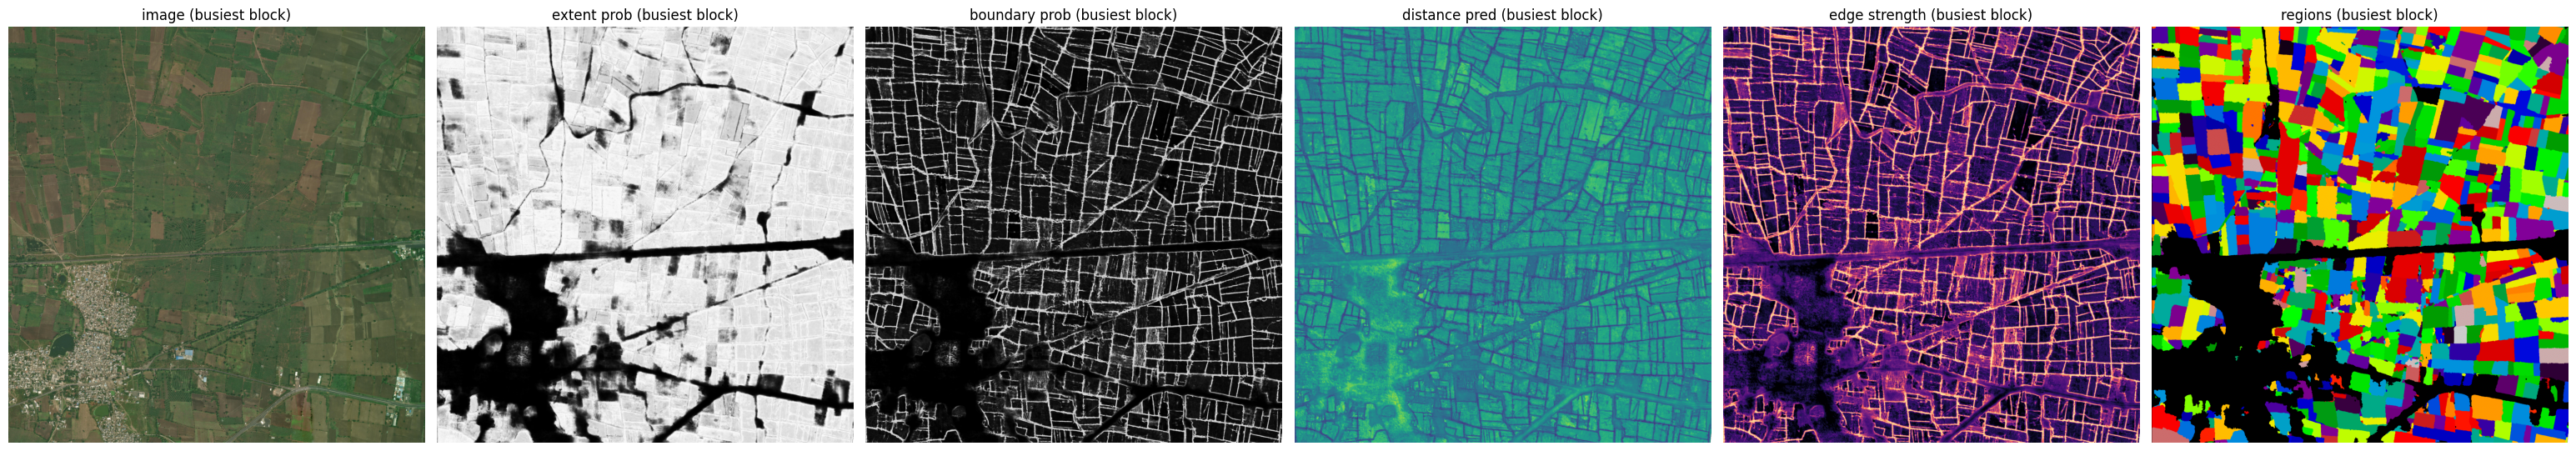

In [9]:
# 8. RUN THE WHOLE VILLAGE -- block by block (flat memory), resumable, then clip + area rules

px_area = abs(transform.a) * abs(transform.e)

# results are cached per block under a signature of the settings, so a Colab disconnect
# can be resumed safely and changed settings never reuse stale blocks
_sig_params = {k: globals()[k] for k in ['OVERSEG_H', 'EXTENT_THRESH', 'MIN_REGION_PX', 'DAGGER_WIDTH_M',
               'SIMPLIFY_FIRST_M', 'SMOOTH_METHOD', 'ANGLE_TOL_DEG', 'SIMPLIFY_AFTER_M', 'SPLIT_OVERSIZED',
               'OVERSIZE_PCTL', 'RESCUE_ORPHANS', 'MAX_FIELD_HA', 'OVERLAP', 'BLOCK_PX', 'MARGIN_PX',
               'SEED_MODE', 'SEED_DIST_MIN', 'SEED_BND_MAX', 'SEED_MIN_PX', 'EDGE_SIGMA', 'DIST_WEIGHT',
               'MERGE_BND_T', 'LABEL_SMOOTH_R', 'VECTOR_MODE', 'COVERAGE_TOL_M']}
_sig_params['HAS_COVERAGE'] = HAS_COVERAGE        # cached blocks must not mix the two vector modes
_sig = hashlib.md5(json.dumps({'p': _sig_params, 'grid': [float(minx), float(maxy), w_px, h_px],
                               'village_ha': round(float(village_area_ha), 1), 'fp16': USE_FP16,
                               'ckpt': [os.path.getsize(CKPT_PATH), int(os.path.getmtime(CKPT_PATH))]},
                              sort_keys=True).encode()).hexdigest()[:8]
BLOCK_DIR = f'{OUT_DIR}/blocks_{_sig}'
os.makedirs(BLOCK_DIR, exist_ok=True)


def process_block(r0, r1, c0, c1):
    """Inference + extraction on the block plus a margin; returns polygons whose centre lies in the core."""
    er0, er1 = max(0, r0 - MARGIN_PX), min(h_px, r1 + MARGIN_PX)
    ec0, ec1 = max(0, c0 - MARGIN_PX), min(w_px, c1 + MARGIN_PX)
    img = mosaic[:, er0:er1, ec0:ec1]
    vm = village_mask[er0:er1, ec0:ec1]
    t = transform * Affine.translation(ec0, er0)

    ep, bp, dp = predict(model, img, fp16=USE_FP16, progress=False)
    if SEED_MODE == 'cores':
        labels, edge, bp_s, info = extract_instances_v2(ep, bp, dp, vm)
    else:
        labels, edge, info = extract_instances(ep, bp, dp, vm)
    if SPLIT_OVERSIZED and labels.max() > 0:
        sizes = np.bincount(labels.ravel())[1:]
        sizes = sizes[sizes > 0] * px_area
        if len(sizes):
            labels = split_oversized(labels, edge, np.percentile(sizes, OVERSIZE_PCTL), px_area, verbose=False)
            labels = split_oversized(labels, edge, MAX_FIELD_HA * 1e4, px_area, verbose=False,
                                     h_ladder=(0.12, 0.08, 0.05, 0.03, 0.02, 0.01))
    n_merged = 0
    if SEED_MODE == 'cores':
        # undo any split (seeding or split_oversized) that has no boundary evidence behind it
        labels, n_merged = merge_weak_boundaries(labels, bp_s, MERGE_BND_T,
                                                 max_area_px=MAX_FIELD_HA * 1e4 / px_area)
        if LABEL_SMOOTH_R > 0:
            labels = drop_small_regions(smooth_labels(labels, LABEL_SMOOTH_R), MIN_REGION_PX)
    info['merged_regions'] = n_merged
    part = polygonize_labels(labels, t, UTM_CRS)

    left, right = minx + c0 * RES_M, minx + c1 * RES_M              # core rectangle in map coordinates
    top, bottom = maxy - r0 * RES_M, maxy - r1 * RES_M
    if len(part):
        rp = part.geometry.representative_point()
        part = part[(rp.x >= left) & (rp.x < right) & (rp.y > bottom) & (rp.y <= top)]
    n_core = len(part)
    part = postprocess_polygons(part) if n_core else part
    stats = dict(info, polys_in_core=n_core, polys_valid=len(part))
    return part, stats, (img, ep, bp, dp, edge, labels, vm)


sample_idx = int(np.argmax([b[4] for b in blocks]))             # block with the most village area, for the QC maps
sample, parts, all_stats = None, [], []
t_run = time.time()
for k, (r0, r1, c0, c1, n_vil) in enumerate(blocks):
    stem = f'{BLOCK_DIR}/b_{r0}_{c0}'
    if os.path.exists(stem + '.gpkg'):
        part = gpd.read_file(stem + '.gpkg'); parts.append(part)
        print(f"[{k + 1}/{len(blocks)}] resumed from cache: {len(part)} polygons"); continue
    if os.path.exists(stem + '.empty'):
        print(f"[{k + 1}/{len(blocks)}] resumed from cache: 0 polygons"); continue

    tb = time.time()
    part, st, arrays = process_block(r0, r1, c0, c1)
    if len(part):
        part.to_file(stem + '.gpkg', driver='GPKG'); parts.append(part)
    else:
        open(stem + '.empty', 'w').close()
    all_stats.append(st)
    if k == sample_idx:
        sample = arrays
    else:
        del arrays
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    print(f"[{k + 1}/{len(blocks)}] rows {r0}-{r1} cols {c0}-{c1} | village {n_vil / (BLOCK_PX ** 2) * 100:3.0f}% of block | "
          f"extent {st['extent_pct_of_village']:.0f}% -> labelled {st['labelled_pct_of_extent']:.0f}% | "
          f"regions {st['final_regions']} (+{st['rescued_regions']} rescued, {st['merged_regions']} merged) | kept {st['polys_valid']} polygons | "
          f"{time.time() - tb:.0f}s")
print(f"all blocks done in {(time.time() - t_run) / 60:.1f} min")
if not parts:
    raise RuntimeError("No polygons produced. Look at the per-block lines above: 'extent' low = the model sees "
                       "no cropland; 'labelled' low = seeding problem.")

# --- global stage: area rules, exact clip, attributes ---------------------------------
gdf = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry='geometry', crs=UTM_CRS)
n_blocks_polys = len(gdf)
min_area_m2 = max(MIN_FIELD_M2, gdf.geometry.area.median() * MIN_AREA_FRAC)
gdf = gdf[gdf.geometry.area >= min_area_m2]
n_after_min_area = len(gdf)
print(f"min-area rule: dropping polygons < {min_area_m2:.0f} m2 ({min_area_m2 / 1e4:.3f} ha) "
      f"[floor {MIN_FIELD_M2} m2, {MIN_AREA_FRAC:.0%} of median]")

if CLIP_TO_VILLAGE:
    gdf['geometry'] = gdf.geometry.intersection(village_geom)
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].explode(index_parts=False)
    gdf = gdf[(gdf.geom_type == 'Polygon') & gdf.geometry.is_valid & (gdf.geometry.area >= min_area_m2)]

gdf = gdf.reset_index(drop=True)
gdf['id'] = np.arange(1, len(gdf) + 1)
gdf['village'] = VILLAGE_NAME
gdf['area_m2'] = gdf.geometry.area.round(1)
gdf['area_ha'] = (gdf.geometry.area / 1e4).round(3)
gdf['perimeter_m'] = gdf.geometry.length.round(1)
gdf['qc'] = np.select([gdf.area_ha < SMALL_FIELD_HA, gdf.area_ha > MAX_FIELD_HA], ['small', 'oversize'], 'ok')
gdf = gdf[['id', 'village', 'area_m2', 'area_ha', 'perimeter_m', 'qc', 'geometry']]
print(f"funnel: {n_blocks_polys} polygons from blocks -> {n_after_min_area} after min-area -> {len(gdf)} after clip")
print("qc flags:", gdf.qc.value_counts().to_dict(),
      f"| 'oversize' = > {MAX_FIELD_HA} ha, likely merged fields or non-crop land -- inspect these")

# --- QC maps for the busiest block -----------------------------------------------------
if sample is not None:
    img, ep, bp, dp, edge, lab, vm = sample
    step = max(1, int(max(vm.shape) / 1500)); sl = (slice(None, None, step), slice(None, None, step))
    v = vm[sl]
    lut = np.zeros(int(lab.max()) + 1, dtype=np.int64)
    lut[1:] = np.random.RandomState(0).permutation(int(lab.max())) + 1
    panels = [('image', img[:, ::step, ::step].transpose(1, 2, 0), None),
              ('extent prob', np.where(v, ep[sl], np.nan), 'gray'),
              ('boundary prob', np.where(v, bp[sl], np.nan), 'gray'),
              ('distance pred', np.where(v, dp[sl], np.nan), 'viridis'),
              ('edge strength', np.where(v, edge[sl], np.nan), 'magma'),
              ('regions', np.where(v, lut[lab[sl]], np.nan), 'nipy_spectral')]
    fig, axes = plt.subplots(1, 6, figsize=(31, 7))
    for ax, (title, arr, cmap) in zip(axes, panels):
        ax.imshow(arr, cmap=cmap); ax.set_title(f'{title} (busiest block)'); ax.axis('off')
    plt.tight_layout(); plt.show()
    sample = None

borgaon_manju: 4094 fields | 4156 ha of 5422 ha village (77% covered)
field size -- median 0.56 ha, p95 3.39, max 20.95

  /content/drive/MyDrive/AI4SF_BD_TF/inference_output/borgaon_manju/borgaon_manju_fields.gpkg   (UTM 43N -- QGIS)
  /content/drive/MyDrive/AI4SF_BD_TF/inference_output/borgaon_manju/borgaon_manju_fields.geojson  (WGS84)
  /content/drive/MyDrive/AI4SF_BD_TF/inference_output/borgaon_manju/borgaon_manju_village_boundary.geojson
  /content/drive/MyDrive/AI4SF_BD_TF/inference_output/borgaon_manju/borgaon_manju_imagery.tif


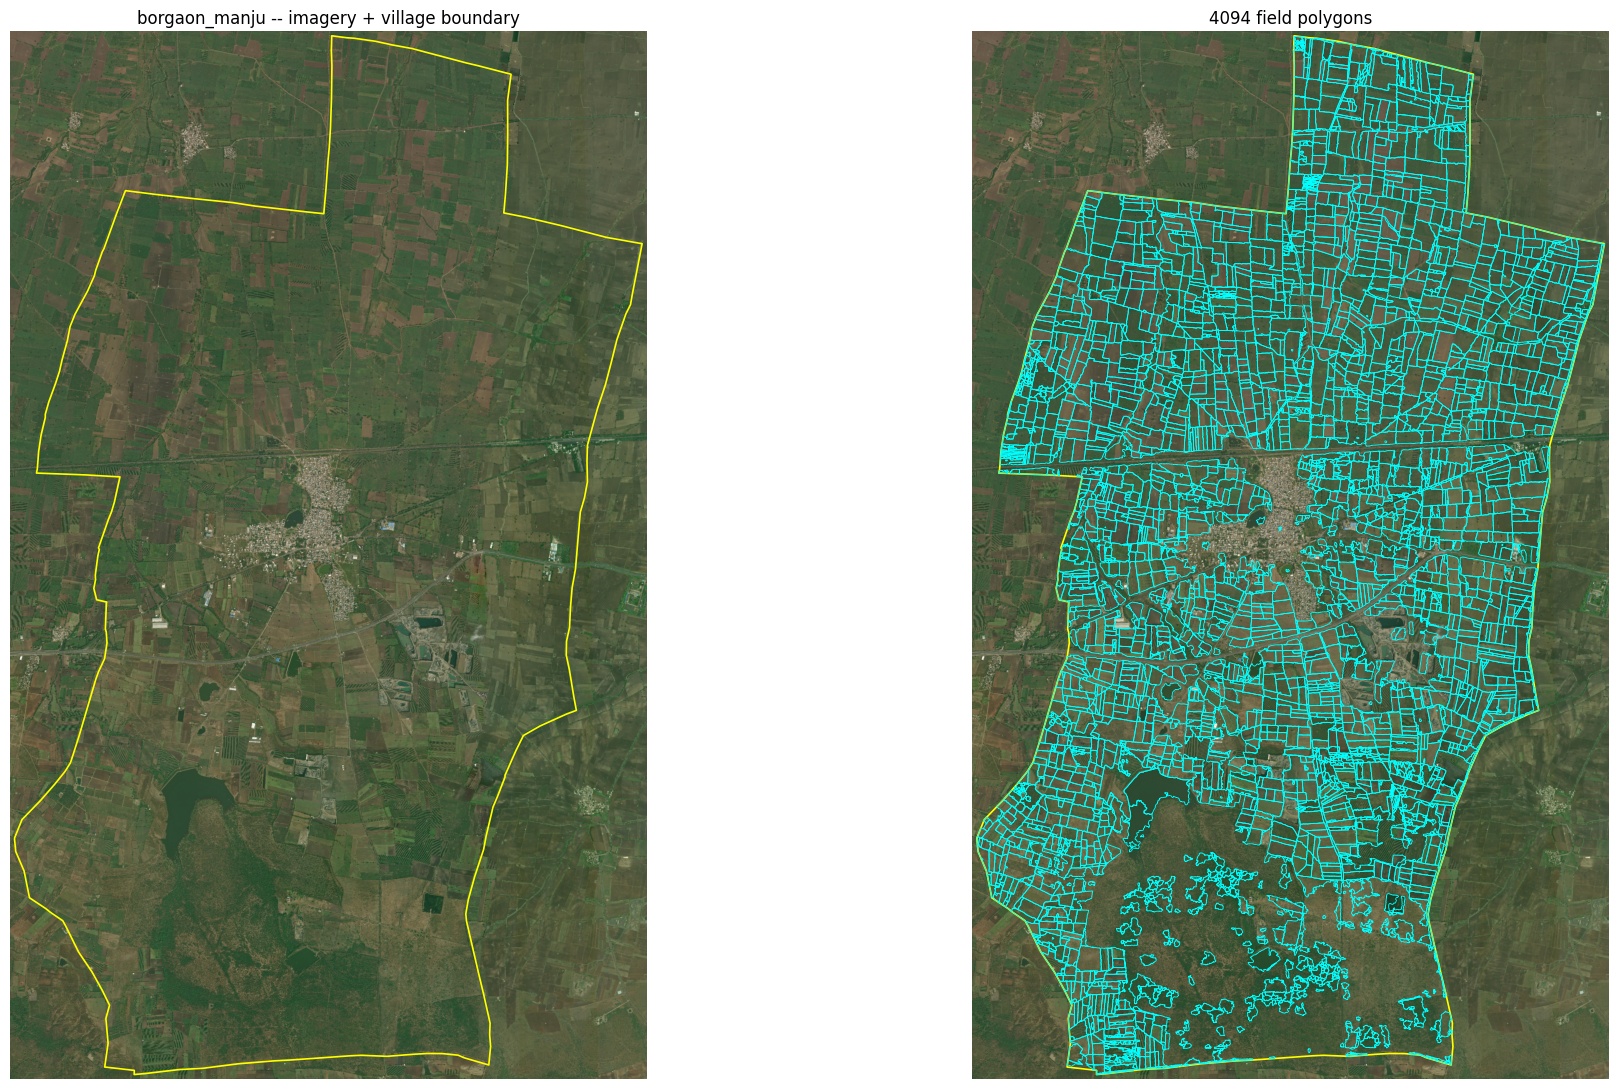

In [10]:
# 8. EXPORT + QC PREVIEW

gpkg  = f'{OUT_DIR}/{SITE_NAME}_fields.gpkg'
gjson = f'{OUT_DIR}/{SITE_NAME}_fields.geojson'
bjson = f'{OUT_DIR}/{SITE_NAME}_village_boundary.geojson'
png   = f'{OUT_DIR}/{SITE_NAME}_preview.png'

gdf.to_file(gpkg, driver='GPKG')
gdf.to_crs('EPSG:4326').to_file(gjson, driver='GeoJSON')
gpd.GeoDataFrame({'village': [VILLAGE_NAME], 'source': [boundary_kind]},
                 geometry=[village_geom], crs=UTM_CRS).to_crs('EPSG:4326').to_file(bjson, driver='GeoJSON')

coverage = gdf.area_ha.sum() / village_area_ha * 100
summary = {
    'village': VILLAGE_NAME, 'boundary_source': boundary_desc, 'village_area_ha': round(village_area_ha, 1),
    'n_fields': int(len(gdf)), 'fields_area_ha': round(float(gdf.area_ha.sum()), 1),
    'field_coverage_pct': round(float(coverage), 1),
    'median_field_ha': round(float(gdf.area_ha.median()), 3),
    'checkpoint': CKPT_PATH,
    'params': {k: globals()[k] for k in ['OVERSEG_H', 'EXTENT_THRESH', 'MIN_REGION_PX', 'DAGGER_WIDTH_M',
                                         'SIMPLIFY_FIRST_M', 'SMOOTH_METHOD', 'ANGLE_TOL_DEG',
                                         'SIMPLIFY_AFTER_M', 'MIN_AREA_FRAC', 'SPLIT_OVERSIZED',
                                         'OVERSIZE_PCTL', 'CLIP_TO_VILLAGE', 'USE_FP16', 'OVERLAP', 'BLOCK_PX', 'MARGIN_PX',
                                         'MIN_FIELD_M2', 'SMALL_FIELD_HA', 'MAX_FIELD_HA', 'RESCUE_ORPHANS',
                                         'SEED_MODE', 'SEED_DIST_MIN', 'SEED_BND_MAX', 'SEED_MIN_PX', 'EDGE_SIGMA',
                                         'DIST_WEIGHT', 'MERGE_BND_T', 'LABEL_SMOOTH_R', 'VECTOR_MODE',
                                         'COVERAGE_TOL_M', 'HAS_COVERAGE']},
    'qc_counts': {k: int(v) for k, v in gdf.qc.value_counts().items()},
}
with open(f'{OUT_DIR}/{SITE_NAME}_run_log.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('=' * 60)
print(f"{VILLAGE_NAME}: {len(gdf)} fields | {gdf.area_ha.sum():.0f} ha of {village_area_ha:.0f} ha village "
      f"({coverage:.0f}% covered)")
print(f"field size -- median {gdf.area_ha.median():.2f} ha, p95 {gdf.area_ha.quantile(0.95):.2f}, "
      f"max {gdf.area_ha.max():.2f}")
print(f"\n  {gpkg}   (UTM 43N -- QGIS)\n  {gjson}  (WGS84)\n  {bjson}\n  {raster_path}")
print('=' * 60)

# preview (decimated so a big village still plots quickly)
step = max(1, int(max(mosaic.shape[1:]) / 3000))
left, top = transform * (0, 0)
right, bottom = transform * (mosaic.shape[2], mosaic.shape[1])
ext = (left, right, bottom, top)
vb = gpd.GeoSeries([village_geom])
fig, axes = plt.subplots(1, 2, figsize=(22, 11))
for ax in axes:
    ax.imshow(mosaic[:, ::step, ::step].transpose(1, 2, 0), extent=ext)
    vb.boundary.plot(ax=ax, color='yellow', linewidth=1.2)
    ax.set_xlim(bminx - 50, bmaxx + 50); ax.set_ylim(bminy - 50, bmaxy + 50); ax.axis('off')
axes[0].set_title(f'{VILLAGE_NAME} -- imagery + village boundary')
gdf.boundary.plot(ax=axes[1], color='cyan', linewidth=0.6)
axes[1].set_title(f'{len(gdf)} field polygons')
plt.tight_layout(); plt.savefig(png, dpi=120); plt.show()